# Proyecto 2 · Análisis exploratorio visual de los frames
## Variables visuales extraídas de los 200 clips

**CC3084 – Ciencia de Datos · Semestre II 2026**


Se muestrearon **10 frames por clip** (2,000 frames) y de cada uno se extrajeron
variables cuantitativas sin usar etiquetas: brillo, contraste, saturación, cobertura
de cancha (`green_ratio`), densidad de bordes y un conteo de blobs de jugador. Este
cuaderno estudia esas variables con estadística descriptiva y gráficos exploratorios.


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('../data/frame_features.csv')
print('Observaciones (frames):', len(df))
print('Variables:', df.shape[1])
df.dtypes


Observaciones (frames): 2000
Variables: 12


file                str
match_id            str
clip_idx          int64
frame_pos         int64
time_s          float64
brightness      float64
contrast        float64
saturation      float64
green_ratio     float64
edge_density    float64
player_count      int64
motion          float64
dtype: object

## 1. Tipos de variables

- **Cuantitativas continuas:** brightness, contrast, saturation, green_ratio,
  edge_density, motion.
- **Cuantitativa discreta:** player_count (proxy por blobs).
- **Categóricas / identificadores:** file, match_id (20 partidos), clip_idx, frame_pos.


In [2]:
num = ['brightness','contrast','saturation','green_ratio','edge_density','motion','player_count']
df[num].describe().round(3)


,brightness,contrast,saturation,green_ratio,edge_density,motion,player_count
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,104.696,45.378,100.307,0.604,0.068,21.705,63.378
std,14.836,6.506,16.943,0.122,0.019,9.850,23.720
min,64.540,27.810,59.840,0.129,0.024,0.000,15.000
25%,98.858,40.680,87.018,0.515,0.055,17.770,48.000
50%,106.465,45.760,99.775,0.612,0.067,22.856,60.000
75%,113.115,49.665,111.982,0.691,0.081,27.502,74.000
max,153.050,69.670,147.490,0.913,0.134,57.583,199.000


## 2. Distribución de las variables cuantitativas (histogramas)


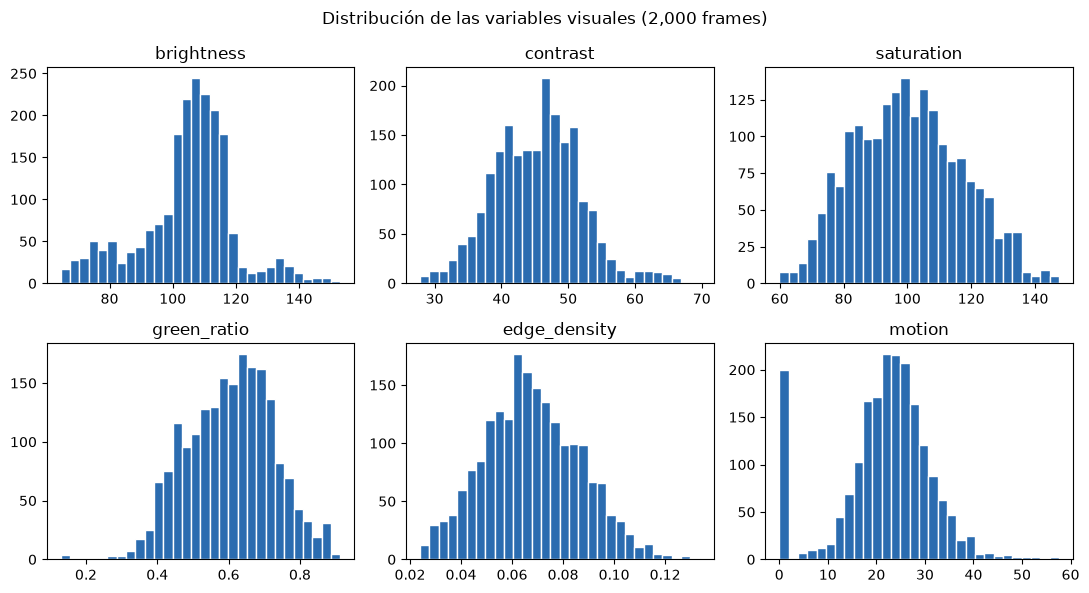

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(11, 6))
for ax, c in zip(axs.ravel(), ['brightness','contrast','saturation','green_ratio','edge_density','motion']):
    ax.hist(df[c], bins=30, color='#2b6cb0', edgecolor='white')
    ax.set_title(c)
fig.suptitle('Distribución de las variables visuales (2,000 frames)')
fig.tight_layout(); fig.savefig('../outputs/08_feature_histograms.png'); plt.show()


**Lectura.** `green_ratio` (cobertura de cancha) es alto en la mayoría de frames
(cámara táctica que enmarca el campo) pero con cola hacia valores bajos: esos frames
son primeros planos, repeticiones o tomas de gradas. El brillo se concentra en un
rango medio; la saturación es alta por el verde del césped.


## 3. Diagramas de caja y detección de outliers


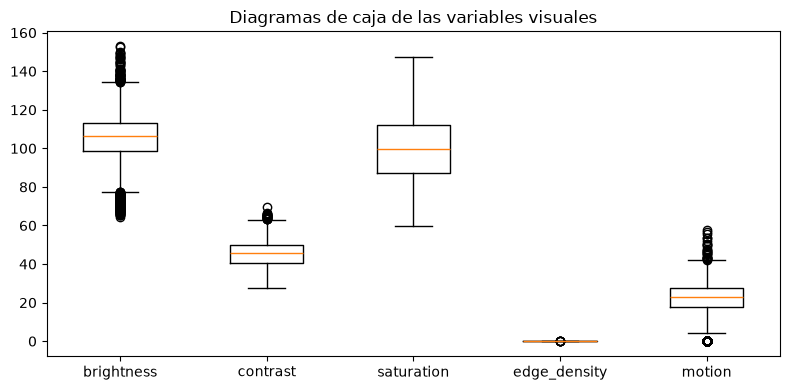

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
cols = ['brightness','contrast','saturation','edge_density','motion']
ax.boxplot([df[c] for c in cols], tick_labels=cols, showfliers=True)
ax.set_title('Diagramas de caja de las variables visuales')
fig.tight_layout(); fig.savefig('../outputs/09_feature_boxplots.png'); plt.show()


In [5]:
# Frames atípicos por baja cobertura de cancha (posibles repeticiones / primeros planos)
q1 = df.green_ratio.quantile(0.05)
outliers = df[df.green_ratio < q1]
print(f'Frames con green_ratio < percentil 5 ({q1:.3f}):', len(outliers))
print('Estos frames tienen, en promedio:')
outliers[['brightness','edge_density','player_count']].mean().round(2)


Frames con green_ratio < percentil 5 (0.408): 100
Estos frames tienen, en promedio:


brightness      79.24
edge_density     0.07
player_count    58.21
dtype: float64

Los frames con poca cancha muestran **más densidad de bordes** (primeros planos con
detalle) — coherente con repeticiones o tomas cerradas. No se eliminan: son parte real
del video y marcan los momentos donde la detección de pases NO es viable.


## 4. Correlación entre variables visuales


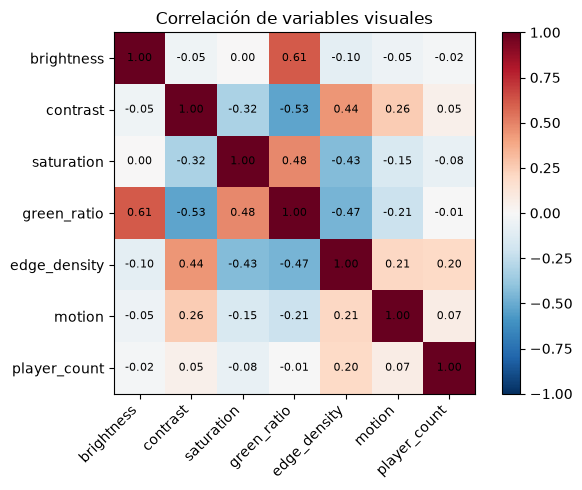

In [6]:
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=45, ha='right')
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, fraction=0.046); ax.set_title('Correlación de variables visuales')
fig.tight_layout(); fig.savefig('../outputs/10_feature_correlation.png'); plt.show()


**Hallazgo.** `green_ratio` correlaciona **negativamente** con `edge_density` y
`saturation` con la cobertura: a más cancha visible, escena más limpia (menos bordes).
Esto confirma que `green_ratio` separa bien las tomas de juego abierto (útiles para
detectar pases) de las tomas cerradas.


## 5. Variación entre partidos (variable categórica `match_id`)


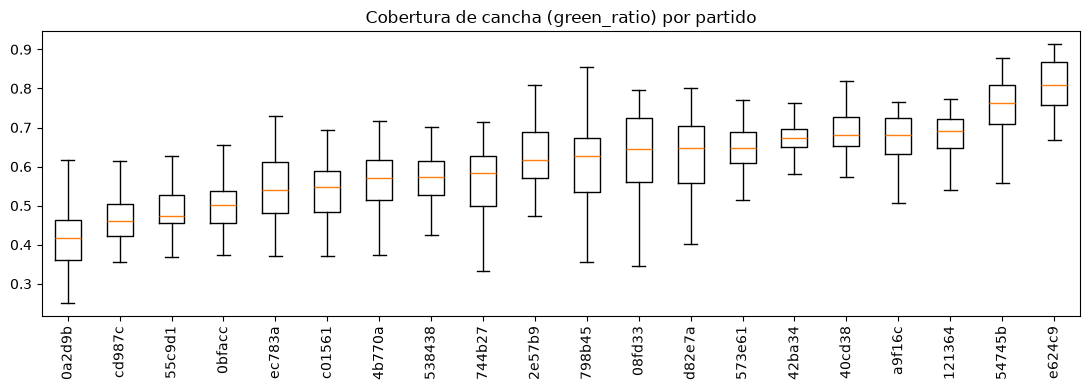

In [7]:
order = df.groupby('match_id').green_ratio.median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([df[df.match_id==m].green_ratio for m in order], tick_labels=order, showfliers=False)
ax.set_title('Cobertura de cancha (green_ratio) por partido')
ax.tick_params(axis='x', rotation=90)
fig.tight_layout(); fig.savefig('../outputs/11_greenratio_by_match.png'); plt.show()


La cobertura de cancha es **consistente entre partidos** (medianas similares), lo que
indica un estilo de transmisión homogéneo — bueno para generalizar un detector.
